<div style="background:linear-gradient(120deg,#4F46E5,#7E22CE);color:#fff;padding:26px 30px;border-radius:14px;font-family:'Segoe UI',IBM Plex Sans,sans-serif">
<div style="font-family:'Consolas',monospace;font-size:0.78rem;opacity:.85;letter-spacing:.12em">INF672 · MACHINE LEARNING · UNIDAD 3 · PRÁCTICA 3</div>
<h1 style="margin:8px 0 4px 0;font-size:1.85rem;font-weight:700">Regresión polinomial</h1>
<div style="font-size:1.05rem;opacity:.95">Predecir el rendimiento de combustible de un automóvil</div>
</div>


**Estudiante:** Abdair Magdiel Coca Carlo · **Materia:** INF672 Machine Learning (UATF) · **Docente:** M. Sc. Húscar F. Gonzales G. · **Unidad 3**

> Cuaderno base de la **Práctica 3**. Los pasos 01–12 forman **un solo flujo**:
> cada uno usa lo que obtuviste en el anterior. Los enunciados están listos: resuelve cada paso en las
> celdas de código (comienzan con un comentario `# Paso …`) y escribe tus interpretaciones en **Tus respuestas**.


<div style="border-left:4px solid #6B7280;background:#F9FAFB;padding:12px 18px;border-radius:0 8px 8px 0;margin:8px 0;font-family:'Segoe UI',sans-serif">
<div style="color:#6B7280;font-weight:700;font-size:0.78rem;letter-spacing:.08em;text-transform:uppercase">Cómo se resuelve</div>
<div style="margin-top:6px;line-height:1.55">
En esta práctica vas a comprobar que un modelo lineal puede ajustar una curva. Entrenarás un modelo de regresión polinomial que prediga el rendimiento de combustible de un automóvil a partir de su potencia, y lo compararás con una regresión lineal simple. Como en la Práctica 2, los pasos forman un solo flujo de trabajo: cada paso usa lo que obtuviste en el anterior. Lee el contexto de cada paso, sigue las instrucciones en orden y responde las preguntas del bloque Para entregar.
</div>
<div style="margin-top:8px;line-height:1.55">
Esta práctica es un <strong>trabajo individual</strong>. Las respuestas escritas deben apoyarse en los resultados que <strong>tú</strong> obtengas al ejecutar tu código: no basta con mostrar números o gráficos, hay que <strong>interpretarlos en el contexto del problema</strong>.
</div>
</div>

<div style="border-left:4px solid #4F46E5;background:#EEF2FF;padding:12px 18px;border-radius:0 8px 8px 0;margin:8px 0;font-family:'Segoe UI',sans-serif">
<div style="color:#4F46E5;font-weight:700;font-size:0.78rem;letter-spacing:.08em;text-transform:uppercase">Entrega</div>
<div style="margin-top:6px;line-height:1.55">
Para entregar tu trabajo desarrolla un notebook de Jupyter que incluya tanto el código ejecutado como tus respuestas escritas en celdas de texto, organizado con un título por cada paso. Súbelo a tu repositorio de GitHub junto con el archivo de datos y envía el enlace a la plataforma virtual en el apartado de <em>Práctica 3</em>.
</div>
</div>


## El problema

### ¿Cuántas millas recorre un auto por galón?

Una organización de defensa del consumidor quiere estimar el rendimiento de combustible de un automóvil conociendo solo su potencia, un dato que aparece en cualquier ficha técnica. Con esa estimación podría advertir a los compradores sobre el consumo esperado de un vehículo antes de adquirirlo.

La intuición dice que a mayor potencia, menor rendimiento. Pero la relación no tiene por qué ser una línea recta: tu tarea es averiguar qué forma tiene, construir un modelo que la represente bien y decidir qué tan complejo debe ser ese modelo.

La regresión polinomial permite ajustar curvas sin abandonar la regresión lineal: se agregan columnas con potencias de la variable de entrada y el modelo sigue siendo lineal en sus coeficientes:

$$\hat{y} = \beta_0 + \beta_1 \cdot x + \beta_2 \cdot x^2 + \dots + \beta_d \cdot x^d$$

donde $d$ es el grado del polinomio. Elegir bien ese grado es una de las decisiones centrales de esta práctica.


## El dataset · archivo `mpg.csv`

El archivo `mpg.csv` (está en esta misma carpeta) contiene **398 filas** (una por automóvil) y **9 columnas**. Es el conjunto de datos público *Auto MPG*, con modelos de automóviles fabricados entre 1970 y 1982. La variable a predecir es `mpg`; en esta práctica usarás como predictor principal `horsepower`.

| Variable | Tipo | Descripción |
|---|---|---|
| `mpg` | Numérica (objetivo) | Rendimiento de combustible: millas recorridas por galón. A mayor valor, menor consumo. |
| `cylinders` | Numérica discreta | Número de cilindros del motor. |
| `displacement` | Numérica | Cilindrada del motor, en pulgadas cúbicas. |
| `horsepower` | Numérica | Potencia del motor, en caballos de fuerza (hp). |
| `weight` | Numérica | Peso del vehículo, en libras. |
| `acceleration` | Numérica | Tiempo, en segundos, para acelerar de 0 a 60 millas por hora. |
| `model_year` | Numérica discreta | Año del modelo, en dos dígitos (70 = 1970). |
| `origin` | Categórica | Región de fabricación: `usa`, `europe` o `japan`. |
| `name` | Texto | Marca y modelo del automóvil. |

<div style="border-left:4px solid #F59E0B;background:#FFFBEB;padding:10px 16px;border-radius:0 8px 8px 0;margin:10px 0;font-family:'Segoe UI',sans-serif">
<div style="color:#B45309;font-weight:700;font-size:0.78rem;letter-spacing:.08em;text-transform:uppercase">Ojo</div>
<div style="margin-top:4px;line-height:1.5">Revisa la calidad de los datos antes de modelar: los modelos de scikit-learn no aceptan valores vacíos, y es tu responsabilidad detectarlos y decidir qué hacer con ellos.</div>
</div>

<div style="display:flex;flex-wrap:wrap;gap:8px;margin:14px 0;font-family:'Segoe UI',sans-serif">
<span style="background:#EEF2FF;color:#4F46E5;border:1px solid #C7D2FE;padding:6px 12px;border-radius:999px;font-size:0.85rem;font-weight:600">01 · Entorno</span>
<span style="background:#EEF2FF;color:#4F46E5;border:1px solid #C7D2FE;padding:6px 12px;border-radius:999px;font-size:0.85rem;font-weight:600">02 · Explorar datos</span>
<span style="background:#EEF2FF;color:#4F46E5;border:1px solid #C7D2FE;padding:6px 12px;border-radius:999px;font-size:0.85rem;font-weight:600">03 · Predictor</span>
<span style="background:#EEF2FF;color:#4F46E5;border:1px solid #C7D2FE;padding:6px 12px;border-radius:999px;font-size:0.85rem;font-weight:600">04 · Limpiar</span>
<span style="background:#EEF2FF;color:#4F46E5;border:1px solid #C7D2FE;padding:6px 12px;border-radius:999px;font-size:0.85rem;font-weight:600">05 · Visualizar</span>
<span style="background:#EEF2FF;color:#4F46E5;border:1px solid #C7D2FE;padding:6px 12px;border-radius:999px;font-size:0.85rem;font-weight:600">06 · Dividir</span>
<span style="background:#EEF2FF;color:#4F46E5;border:1px solid #C7D2FE;padding:6px 12px;border-radius:999px;font-size:0.85rem;font-weight:600">07 · Lineal base</span>
<span style="background:#EEF2FF;color:#4F46E5;border:1px solid #C7D2FE;padding:6px 12px;border-radius:999px;font-size:0.85rem;font-weight:600">08 · Grado 2</span>
<span style="background:#EEF2FF;color:#4F46E5;border:1px solid #C7D2FE;padding:6px 12px;border-radius:999px;font-size:0.85rem;font-weight:600">09 · Validación cruzada</span>
<span style="background:#EEF2FF;color:#4F46E5;border:1px solid #C7D2FE;padding:6px 12px;border-radius:999px;font-size:0.85rem;font-weight:600">10 · Evaluar</span>
<span style="background:#EEF2FF;color:#4F46E5;border:1px solid #C7D2FE;padding:6px 12px;border-radius:999px;font-size:0.85rem;font-weight:600">11 · Predecir</span>
<span style="background:#EEF2FF;color:#4F46E5;border:1px solid #C7D2FE;padding:6px 12px;border-radius:999px;font-size:0.85rem;font-weight:600">12 · Conclusiones</span>
<span style="background:#EEF2FF;color:#4F46E5;border:1px solid #C7D2FE;padding:6px 12px;border-radius:999px;font-size:0.85rem;font-weight:600">Reto · Multivariable</span>
</div>


<div style="background:linear-gradient(120deg,#4F46E5,#7E22CE);color:#fff;padding:14px 20px;border-radius:10px;margin-top:22px;font-family:'Segoe UI',sans-serif">
<div style="font-family:'Consolas',monospace;font-size:0.72rem;opacity:.85;letter-spacing:.12em">PASO 01</div>
<div style="font-size:1.25rem;font-weight:700">Preparar el entorno de trabajo</div>
</div>

Además de las librerías que ya usaste en la Práctica 2, necesitarás herramientas para transformar variables, encadenar pasos y validar modelos.

1. Crea un notebook nuevo y coloca el archivo `mpg.csv` en la misma carpeta.
2. Importa `pandas`, `numpy` y `matplotlib.pyplot`.
3. Desde scikit-learn importa: `train_test_split`, `cross_val_score` y `KFold` (módulo `model_selection`); `PolynomialFeatures` y `StandardScaler` (módulo `preprocessing`); `LinearRegression` (módulo `linear_model`); `make_pipeline` (módulo `pipeline`); y las métricas `mean_squared_error` y `r2_score` (módulo `metrics`).

<div style="border-left:4px solid #7E22CE;background:#F5F3FF;padding:12px 18px;border-radius:0 8px 8px 0;margin:12px 0;font-family:'Segoe UI',sans-serif">
<div style="color:#7E22CE;font-weight:700;font-size:0.78rem;letter-spacing:.08em;text-transform:uppercase">Para entregar · Paso 01</div>
<ul style="margin:6px 0 0 0;padding-left:18px;line-height:1.55">
<li>La celda de importaciones <strong>ejecutada sin errores</strong>.</li>
<li>Una tabla breve que indique, con tus palabras, <strong>para qué usarás cada función importada de scikit-learn</strong>.</li>
</ul>
</div>


In [1]:
# Paso 01: importar pandas, numpy, matplotlib.pyplot y las funciones de scikit-learn
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score

print("Librerias importadas sin errores.")

Librerias importadas sin errores.


<div style="background:#059669;color:#fff;padding:8px 16px;border-radius:8px;font-family:'Segoe UI',sans-serif;font-weight:700;font-size:0.95rem;display:inline-block">Tus respuestas · Paso 01</div>

### División de datos y validación cruzada
`from sklearn.model_selection import train_test_split, cross_val_score, KFold`

### Preprocesamiento de datos
`from sklearn.preprocessing import PolynomialFeatures, StandardScaler`

### Modelo de regresión lineal
`from sklearn.linear_model import LinearRegression`

### Creación de pipelines
`from sklearn.pipeline import make_pipeline`

### Métricas de evaluación
`from sklearn.metrics import mean_squared_error, r2_score`

<div style="background:linear-gradient(120deg,#4F46E5,#7E22CE);color:#fff;padding:14px 20px;border-radius:10px;margin-top:22px;font-family:'Segoe UI',sans-serif">
<div style="font-family:'Consolas',monospace;font-size:0.72rem;opacity:.85;letter-spacing:.12em">PASO 02</div>
<div style="font-size:1.25rem;font-weight:700">Cargar y explorar los datos</div>
</div>

Antes de elegir un modelo hay que conocer la tabla: cuántos registros hay, de qué tipo es cada columna y si falta información.

1. Carga el archivo con `pd.read_csv` y muestra sus dimensiones y primeras filas.
2. Revisa los tipos de datos con `df.info()` y cuenta los valores faltantes por columna con `df.isna().sum()`.
3. Obtén un resumen estadístico de las variables numéricas con `df.describe()`.

<div style="border-left:4px solid #7E22CE;background:#F5F3FF;padding:12px 18px;border-radius:0 8px 8px 0;margin:12px 0;font-family:'Segoe UI',sans-serif">
<div style="color:#7E22CE;font-weight:700;font-size:0.78rem;letter-spacing:.08em;text-transform:uppercase">Para entregar · Paso 02</div>
<div style="margin-top:6px">Las salidas de las instrucciones. Responde:</div>
<ul style="margin:6px 0 0 0;padding-left:18px;line-height:1.55">
<li>¿Cuántos automóviles y columnas tiene el dataset?</li>
<li>¿Hay valores faltantes? ¿En qué columna y cuántos?</li>
<li>¿Entre qué valores varían `mpg` y `horsepower`?</li>
</ul>
</div>


In [6]:
# Paso 02a: cargar mpg.csv, ver dimensiones y primeras filas
df = pd.read_csv("mpg.csv")

#dimensiones del dataset
print(df.shape)

#los primeros 5 datos del dataset
df.head()

(398, 9)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


In [12]:
# Paso 02b: tipos de datos, valores faltantes y resumen estadístico

# mostramos el tipo de dato de cada columna
df.info()

# contamos los datos faltantes de cada columna
df.isna().sum()

# nos muestra el resumen estadistico del dataset
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    str    
 8   name          398 non-null    str    
dtypes: float64(4), int64(3), str(2)
memory usage: 28.1 KB


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year
count,398.000000,398.000000,398.000000,392.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,104.469388,2970.424623,15.568090,76.010050
std,7.815984,1.701004,104.269838,38.491160,846.841774,2.757689,3.697627
min,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000
25%,17.500000,4.000000,104.250000,75.000000,2223.750000,13.825000,73.000000
50%,23.000000,4.000000,148.500000,93.500000,2803.500000,15.500000,76.000000
75%,29.000000,8.000000,262.000000,126.000000,3608.000000,17.175000,79.000000
max,46.600000,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000


<div style="background:#059669;color:#fff;padding:8px 16px;border-radius:8px;font-family:'Segoe UI',sans-serif;font-weight:700;font-size:0.95rem;display:inline-block">Tus respuestas · Paso 02</div>

<ul style="margin:6px 0 0 0;padding-left:18px;line-height:1.55">
<li>¿Cuántos automóviles y columnas tiene el dataset?</li>
R. hay 398 automoviles y cada uno tiene 9 columnas
<li>¿Hay valores faltantes? ¿En qué columna y cuántos?</li>
R. hay en la columna horsepower con 6 datos faltantes
<li>¿Entre qué valores varían `mpg` y `horsepower`?</li>
R. mpg varía entre 9.0 y 46.6 millas por galón; horsepower entre 46 y 230 hp
</ul>

<div style="background:linear-gradient(120deg,#4F46E5,#7E22CE);color:#fff;padding:14px 20px;border-radius:10px;margin-top:22px;font-family:'Segoe UI',sans-serif">
<div style="font-family:'Consolas',monospace;font-size:0.72rem;opacity:.85;letter-spacing:.12em">PASO 03</div>
<div style="font-size:1.25rem;font-weight:700">Elegir el predictor</div>
</div>

Esta práctica usa una sola variable de entrada. Para justificar la elección, conviene medir qué tan relacionada está cada variable numérica con `mpg`.

1. Calcula la correlación de cada variable numérica con `mpg`. Puedes seleccionar las columnas numéricas con `df.select_dtypes("number")` y usar el método `.corr()`.
2. Ordena los resultados para identificar las relaciones más fuertes.

<div style="border-left:4px solid #7E22CE;background:#F5F3FF;padding:12px 18px;border-radius:0 8px 8px 0;margin:12px 0;font-family:'Segoe UI',sans-serif">
<div style="color:#7E22CE;font-weight:700;font-size:0.78rem;letter-spacing:.08em;text-transform:uppercase">Para entregar · Paso 03</div>
<div style="margin-top:6px">La tabla de correlaciones ordenada. Responde:</div>
<ul style="margin:6px 0 0 0;padding-left:18px;line-height:1.55">
<li>¿Qué variables tienen la relación más fuerte con `mpg`?</li>
<li>¿Qué significa el signo de esas correlaciones en términos del auto?</li>
<li>Recuerda que la correlación de Pearson mide solo relaciones lineales: ¿por qué una variable con una relación claramente curva podría ser un buen candidato para la regresión polinomial aunque su correlación no sea la más alta?</li>
</ul>
</div>


In [19]:
# Paso 03: correlación de cada variable numérica con mpg, ordenada
df.select_dtypes("number").corr().sort_values("mpg", ascending=False)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year
mpg,1.000000,-0.775396,-0.804203,-0.778427,-0.831741,0.420289,0.579267
model_year,0.579267,-0.348746,-0.370164,-0.416361,-0.306564,0.288137,1.000000
acceleration,0.420289,-0.505419,-0.543684,-0.689196,-0.417457,1.000000,0.288137
cylinders,-0.775396,1.000000,0.950721,0.842983,0.896017,-0.505419,-0.348746
horsepower,-0.778427,0.842983,0.897257,1.000000,0.864538,-0.689196,-0.416361
displacement,-0.804203,0.950721,1.000000,0.897257,0.932824,-0.543684,-0.370164
weight,-0.831741,0.896017,0.932824,0.864538,1.000000,-0.417457,-0.306564


<div style="background:#059669;color:#fff;padding:8px 16px;border-radius:8px;font-family:'Segoe UI',sans-serif;font-weight:700;font-size:0.95rem;display:inline-block">Tus respuestas · Paso 03</div>

<ul style="margin:6px 0 0 0;padding-left:18px;line-height:1.55">
<li>¿Qué variables tienen la relación más fuerte con `mpg`?</li>
R. weight y displacement
<li>¿Qué significa el signo de esas correlaciones en términos del auto?</li>
R. que entre mas alejado este de 0 tiende a ser mas inestable
<li>Recuerda que la correlación de Pearson mide solo relaciones lineales: ¿por qué una variable con una relación claramente curva podría ser un buen candidato para la regresión polinomial aunque su correlación no sea la más alta?</li>
R. si representa bien la curva que tiende la correlacion es buen candidato para la regresion polinomial
</ul>

<div style="background:linear-gradient(120deg,#4F46E5,#7E22CE);color:#fff;padding:14px 20px;border-radius:10px;margin-top:22px;font-family:'Segoe UI',sans-serif">
<div style="font-family:'Consolas',monospace;font-size:0.72rem;opacity:.85;letter-spacing:.12em">PASO 04</div>
<div style="font-size:1.25rem;font-weight:700">Limpiar los datos</div>
</div>

El modelo solo necesita dos columnas: `horsepower` como entrada y `mpg` como objetivo. Las filas con valores faltantes en esas columnas deben tratarse antes de entrenar.

1. Crea un nuevo DataFrame, llamado `datos`, que contenga solo las columnas `horsepower` y `mpg`.
2. Elimina las filas con valores faltantes usando `dropna()`.
3. Imprime cuántas filas quedaron.

<div style="border-left:4px solid #7E22CE;background:#F5F3FF;padding:12px 18px;border-radius:0 8px 8px 0;margin:12px 0;font-family:'Segoe UI',sans-serif">
<div style="color:#7E22CE;font-weight:700;font-size:0.78rem;letter-spacing:.08em;text-transform:uppercase">Para entregar · Paso 04</div>
<div style="margin-top:6px">El número de filas antes y después de la limpieza. Responde:</div>
<ul style="margin:6px 0 0 0;padding-left:18px;line-height:1.55">
<li>¿Qué porcentaje de los datos eliminaste?</li>
<li>¿Por qué en este caso es razonable eliminar esas filas en lugar de rellenarlas?</li>
<li>¿En qué situación preferirías imputar los valores?</li>
</ul>
</div>


In [34]:
# Paso 04: crear datos (horsepower, mpg), aplicar dropna e imprimir filas restantes
datos = df[["horsepower", "mpg"]]
datos = datos.dropna()
print("Porcentaje : ",((len(df)-len(datos))*100)/len(df))

Porcentaje :  1.5075376884422111


,horsepower,mpg
0,130.0,18.0
1,165.0,15.0
2,150.0,18.0
3,150.0,16.0
4,140.0,17.0
...,...,...
393,86.0,27.0
394,52.0,44.0
395,84.0,32.0
396,79.0,28.0


<div style="background:#059669;color:#fff;padding:8px 16px;border-radius:8px;font-family:'Segoe UI',sans-serif;font-weight:700;font-size:0.95rem;display:inline-block">Tus respuestas · Paso 04</div>
<ul style="margin:6px 0 0 0;padding-left:18px;line-height:1.55">
<li>¿Qué porcentaje de los datos eliminaste?</li>
R. 1.51 %
<li>¿Por qué en este caso es razonable eliminar esas filas en lugar de rellenarlas?</li>
R. Porque afectan directamente al resultado, porque son datos de horsepower
<li>¿En qué situación preferirías imputar los valores?</li>
R.Se prefiere imputar valores nulos cuando eliminar las filas supondría perder demasiada información útil o cuando los datos son importantes para el análisis y podemos estimar razonablemente los valores faltantes.
</ul>



<div style="background:linear-gradient(120deg,#4F46E5,#7E22CE);color:#fff;padding:14px 20px;border-radius:10px;margin-top:22px;font-family:'Segoe UI',sans-serif">
<div style="font-family:'Consolas',monospace;font-size:0.72rem;opacity:.85;letter-spacing:.12em">PASO 05</div>
<div style="font-size:1.25rem;font-weight:700">Visualizar la relación</div>
</div>

Antes de entrenar cualquier modelo conviene mirar los datos. Un diagrama de dispersión muestra si la relación entre dos variables es recta o curva, y eso decide qué tipo de modelo necesitas.

1. Dibuja un diagrama de dispersión con `horsepower` en el eje horizontal y `mpg` en el vertical.
2. Agrega título, etiquetas con unidades en los ejes y una cuadrícula.

<div style="border-left:4px solid #7E22CE;background:#F5F3FF;padding:12px 18px;border-radius:0 8px 8px 0;margin:12px 0;font-family:'Segoe UI',sans-serif">
<div style="color:#7E22CE;font-weight:700;font-size:0.78rem;letter-spacing:.08em;text-transform:uppercase">Para entregar · Paso 05</div>
<div style="margin-top:6px">El gráfico y una descripción escrita de la forma de la relación. Responde:</div>
<ul style="margin:6px 0 0 0;padding-left:18px;line-height:1.55">
<li>¿El rendimiento disminuye al mismo ritmo en todo el rango de potencias?</li>
<li>¿Crees que una recta podrá representar bien estos datos? Justifica señalando zonas concretas del gráfico.</li>
</ul>
</div>


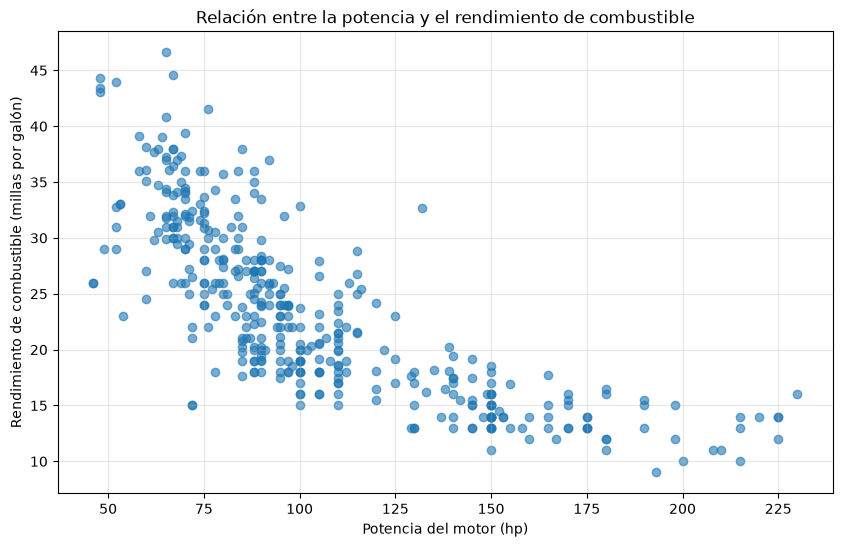

In [42]:
# Paso 05: dispersión horsepower vs mpg con título, etiquetas y cuadrícula
plt.figure(figsize=(10, 6))

plt.scatter(
    datos["horsepower"],
    datos["mpg"],
    alpha=0.6
)

plt.title("Relación entre la potencia y el rendimiento de combustible")
plt.xlabel("Potencia del motor (hp)")
plt.ylabel("Rendimiento de combustible (millas por galón)")
plt.grid(True, alpha=0.3)

plt.show()

<div style="background:#059669;color:#fff;padding:8px 16px;border-radius:8px;font-family:'Segoe UI',sans-serif;font-weight:700;font-size:0.95rem;display:inline-block">Tus respuestas · Paso 05</div>
<ul style="margin:6px 0 0 0;padding-left:18px;line-height:1.55">
<li>¿El rendimiento disminuye al mismo ritmo en todo el rango de potencias?</li>
R. No, se ve una tendencia en curva
<li>¿Crees que una recta podrá representar bien estos datos? Justifica señalando zonas concretas del gráfico.</li>
R. No, cuando la potencia del motor esta en 100 hp se nota una tendencia en curva
</ul>


<div style="background:linear-gradient(120deg,#4F46E5,#7E22CE);color:#fff;padding:14px 20px;border-radius:10px;margin-top:22px;font-family:'Segoe UI',sans-serif">
<div style="font-family:'Consolas',monospace;font-size:0.72rem;opacity:.85;letter-spacing:.12em">PASO 06</div>
<div style="font-size:1.25rem;font-weight:700">Dividir en entrenamiento y prueba</div>
</div>

Como en la práctica anterior, el modelo se evaluará con datos que no usó para aprender. Esta vez, además, el conjunto de prueba deberá quedar reservado hasta el final: las decisiones sobre el modelo se tomarán solo con los datos de entrenamiento.

1. Define `X` con la columna `horsepower` usando doble corchete (`datos[["horsepower"]]`) e `y` con la columna `mpg`.
2. Divide los datos con `train_test_split`, reservando el 20 % para prueba y usando `random_state=42`.
3. Imprime cuántas filas quedaron en cada conjunto.

<div style="border-left:4px solid #7E22CE;background:#F5F3FF;padding:12px 18px;border-radius:0 8px 8px 0;margin:12px 0;font-family:'Segoe UI',sans-serif">
<div style="color:#7E22CE;font-weight:700;font-size:0.78rem;letter-spacing:.08em;text-transform:uppercase">Para entregar · Paso 06</div>
<div style="margin-top:6px">El tamaño de cada conjunto. Responde:</div>
<ul style="margin:6px 0 0 0;padding-left:18px;line-height:1.55">
<li>¿Por qué `X` se define con doble corchete y `y` con uno solo?</li>
<li>¿Qué forma (`.shape`) tiene cada uno y por qué scikit-learn exige esa diferencia?</li>
</ul>
</div>


In [44]:
# Paso 06: definir X e y, dividir 80/20 con train_test_split (random_state=42)
x = datos[["horsepower"]]
y = datos["mpg"]
print(x.shape, y.shape)

X_train, X_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42
)

(392, 1) (392,)


<div style="background:#059669;color:#fff;padding:8px 16px;border-radius:8px;font-family:'Segoe UI',sans-serif;font-weight:700;font-size:0.95rem;display:inline-block">Tus respuestas · Paso 06</div>

<ul style="margin:6px 0 0 0;padding-left:18px;line-height:1.55">
<li>¿Por qué `X` se define con doble corchete y `y` con uno solo?</li>
R. Porque Scikit-learn espera una entrada bidimensional y y en cambio puede ser unidimensional
<li>¿Qué forma (`.shape`) tiene cada uno y por qué scikit-learn exige esa diferencia?</li>
R. x es bidimencioanl tiene (392,1) y y tiene (392,), porque estamos usando regresion polinomial y se espera una variable bidmensional
</ul>

<div style="background:linear-gradient(120deg,#4F46E5,#7E22CE);color:#fff;padding:14px 20px;border-radius:10px;margin-top:22px;font-family:'Segoe UI',sans-serif">
<div style="font-family:'Consolas',monospace;font-size:0.72rem;opacity:.85;letter-spacing:.12em">PASO 07</div>
<div style="font-size:1.25rem;font-weight:700">Entrenar el modelo base: regresión lineal</div>
</div>

El primer modelo es una regresión lineal simple, ŷ = β₀ + β₁·x. Sirve como punto de comparación: el modelo polinomial solo vale la pena si la supera. Usarás dos métricas: el RMSE (raíz del error cuadrático medio), que expresa el error en las mismas unidades que `mpg`, y el R².

1. Entrena un modelo `LinearRegression` con los datos de entrenamiento.
2. Predice el conjunto de prueba y calcula el RMSE (raíz cuadrada de `mean_squared_error`) y el R².

<div style="border-left:4px solid #7E22CE;background:#F5F3FF;padding:12px 18px;border-radius:0 8px 8px 0;margin:12px 0;font-family:'Segoe UI',sans-serif">
<div style="color:#7E22CE;font-weight:700;font-size:0.78rem;letter-spacing:.08em;text-transform:uppercase">Para entregar · Paso 07</div>
<div style="margin-top:6px">Los valores de RMSE y R² del modelo lineal. Responde:</div>
<ul style="margin:6px 0 0 0;padding-left:18px;line-height:1.55">
<li>¿Qué significa el RMSE en millas por galón?</li>
<li>¿Qué proporción de la variación del rendimiento explica este modelo?</li>
</ul>
</div>


In [47]:
# Paso 07: entrenar regresión lineal base y calcular RMSE y R² de prueba
modelo_lineal = LinearRegression()

modelo_lineal.fit(
    X_train, 
    y_train
) 
y_pred = modelo_lineal.predict(X_test)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("RMSE: ", rmse)
print("R2: ", r2)

RMSE:  4.706722545876633
R2:  0.5659681822256184


<div style="background:#059669;color:#fff;padding:8px 16px;border-radius:8px;font-family:'Segoe UI',sans-serif;font-weight:700;font-size:0.95rem;display:inline-block">Tus respuestas · Paso 07</div>

<ul style="margin:6px 0 0 0;padding-left:18px;line-height:1.55">
<li>¿Qué significa el RMSE en millas por galón?</li>
R. que es el tamaño tipico del error de la prediccion que es en aproximadamente 4.71
<li>¿Qué proporción de la variación del rendimiento explica este modelo?</li>
R. El modelo explica que el 56.596% de variabilidad del modelo, el resto no puede ser explicado.
</ul>

<div style="background:linear-gradient(120deg,#4F46E5,#7E22CE);color:#fff;padding:14px 20px;border-radius:10px;margin-top:22px;font-family:'Segoe UI',sans-serif">
<div style="font-family:'Consolas',monospace;font-size:0.72rem;opacity:.85;letter-spacing:.12em">PASO 08</div>
<div style="font-size:1.25rem;font-weight:700">Entrenar un modelo polinomial de grado 2</div>
</div>

Un pipeline encadena varios pasos que se aplican siempre en el mismo orden, tanto al entrenar como al predecir. Para la regresión polinomial usarás tres: escalar la variable, generar sus potencias y ajustar una regresión lineal sobre las nuevas columnas.

1. Construye un pipeline con `make_pipeline(StandardScaler(), PolynomialFeatures(degree=2), LinearRegression())`, entrénalo y calcula sus métricas de prueba.
2. Accede a los pasos del pipeline con `named_steps` y muestra las columnas que `PolynomialFeatures` genera para los tres primeros autos de entrenamiento. Usa `get_feature_names_out` para ponerles nombre.
3. Dibuja en un mismo gráfico los puntos de entrenamiento y de prueba, la recta del modelo lineal y la curva del modelo polinomial. Para trazar líneas suaves genera 200 valores ordenados de potencia con `np.linspace`.

<div style="border-left:4px solid #7E22CE;background:#F5F3FF;padding:12px 18px;border-radius:0 8px 8px 0;margin:12px 0;font-family:'Segoe UI',sans-serif">
<div style="color:#7E22CE;font-weight:700;font-size:0.78rem;letter-spacing:.08em;text-transform:uppercase">Para entregar · Paso 08</div>
<div style="margin-top:6px">Las métricas de ambos modelos, la tabla de columnas generadas y el gráfico comparativo. Responde:</div>
<ul style="margin:6px 0 0 0;padding-left:18px;line-height:1.55">
<li>¿Qué columnas crea `PolynomialFeatures` y qué representa cada una?</li>
<li>¿Por qué se escala la variable antes de elevarla al cuadrado?</li>
<li>¿En qué zonas del gráfico la recta se equivoca más y cómo lo corrige la curva?</li>
</ul>
</div>


In [50]:
# Paso 08a: pipeline grado 2 (scaler + PolynomialFeatures + LinearRegression) y métricas
poly = PolynomialFeatures(degree=2) 
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)
print("Forma original:", X_train.shape)
print("Forma polinomial:", X_train_poly.shape)

modelo_poly = LinearRegression()

modelo_poly.fit(X_train_poly, y_train)

y_pred_poly = modelo_poly.predict(X_test_poly)

rmse_poly = np.sqrt(mean_squared_error(y_test, y_pred_poly))
r2_poly = r2_score(y_test, y_pred_poly)

print("RMSE polinomial:", rmse_poly)
print("R² polinomial:", r2_poly)

Forma original: (313, 1)
Forma polinomial: (313, 3)
RMSE polinomial: 4.291499481069298
R² polinomial: 0.639170114701326


In [51]:
# Paso 08b: columnas generadas por PolynomialFeatures
nombres_columnas = poly.get_feature_names_out(X_train.columns)

print("Columnas originales:")
print(X_train.columns.tolist())

print("\nColumnas polinomiales:")
print(nombres_columnas)

Columnas originales:
['horsepower']

Columnas polinomiales:
['1' 'horsepower' 'horsepower^2']


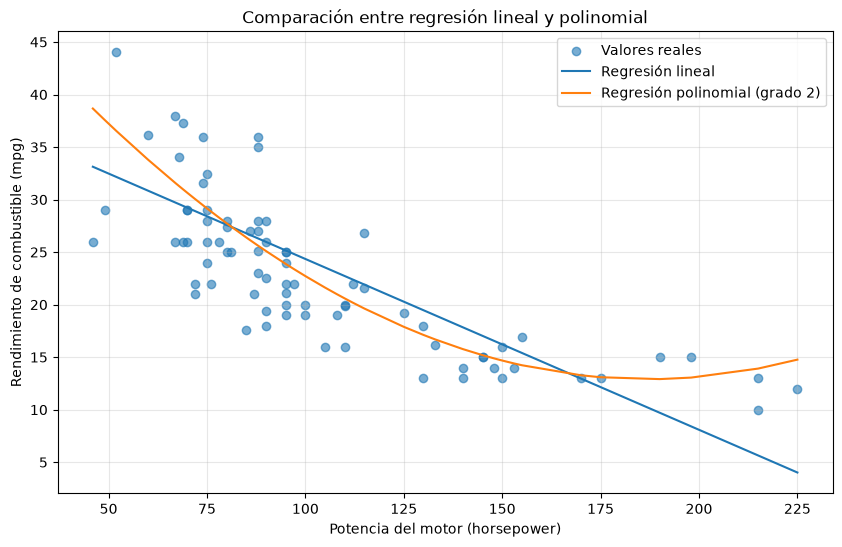

In [52]:
# Paso 08c: gráfico comparativo

# Convertir X_test a un arreglo unidimensional y ordenar sus valores
x_test_valores = X_test["horsepower"].to_numpy()
orden = np.argsort(x_test_valores)

x_ordenado = x_test_valores[orden]
y_lineal_ordenado = y_pred[orden]
y_poly_ordenado = y_pred_poly[orden]

plt.figure(figsize=(10, 6))

# Datos reales
plt.scatter(
    x_test_valores,
    y_test,
    alpha=0.6,
    label="Valores reales"
)

# Predicciones de ambos modelos
plt.plot(
    x_ordenado,
    y_lineal_ordenado,
    label="Regresión lineal"
)

plt.plot(
    x_ordenado,
    y_poly_ordenado,
    label="Regresión polinomial (grado 2)"
)

plt.title("Comparación entre regresión lineal y polinomial")
plt.xlabel("Potencia del motor (horsepower)")
plt.ylabel("Rendimiento de combustible (mpg)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

<div style="background:#059669;color:#fff;padding:8px 16px;border-radius:8px;font-family:'Segoe UI',sans-serif;font-weight:700;font-size:0.95rem;display:inline-block">Tus respuestas · Paso 08</div>

<ul style="margin:6px 0 0 0;padding-left:18px;line-height:1.55">
<li>¿Qué columnas crea `PolynomialFeatures` y qué representa cada una?</li>
R. crea 1 y horsepower^2 que 1 significa el termino constante o intercepto, y horsepower^2 es la potencia del auto elevado al cuadrado
<li>¿Por qué se escala la variable antes de elevarla al cuadrado?</li>
R. para que los datos sean mucho mas manejables, es diferente elevar al cuadrado un 200 a que un 2.1 o numeros pequenos.
<li>¿En qué zonas del gráfico la recta se equivoca más y cómo lo corrige la curva?</li>
R. tiende a equivocarse al principio, al medio y al final, lo que claramente se ve como una curva, en el cual la curva lo descrobe muy bien.
</ul>

<div style="background:linear-gradient(120deg,#4F46E5,#7E22CE);color:#fff;padding:14px 20px;border-radius:10px;margin-top:22px;font-family:'Segoe UI',sans-serif">
<div style="font-family:'Consolas',monospace;font-size:0.72rem;opacity:.85;letter-spacing:.12em">PASO 09</div>
<div style="font-size:1.25rem;font-weight:700">Elegir el grado con validación cruzada</div>
</div>

Un grado muy bajo no captura la curva (subajuste); uno muy alto se adapta al ruido de los datos de entrenamiento (sobreajuste). Para elegir el grado sin usar el conjunto de prueba se aplica validación cruzada sobre los datos de entrenamiento.

1. Define una validación cruzada de 10 pliegues con `KFold(n_splits=10, shuffle=True, random_state=42)`.
2. Para cada grado de 1 a 10, construye el mismo pipeline del Paso 08 y calcula el RMSE medio con `cross_val_score` usando `scoring="neg_root_mean_squared_error"`. Ten en cuenta que scikit-learn devuelve este error con signo negativo.
3. Organiza los resultados en una tabla y dibuja el RMSE de validación cruzada en función del grado.
4. Identifica el grado con menor error y decide qué grado usarás en el modelo final.

<div style="border-left:4px solid #7E22CE;background:#F5F3FF;padding:12px 18px;border-radius:0 8px 8px 0;margin:12px 0;font-family:'Segoe UI',sans-serif">
<div style="color:#7E22CE;font-weight:700;font-size:0.78rem;letter-spacing:.08em;text-transform:uppercase">Para entregar · Paso 09</div>
<div style="margin-top:6px">La tabla y el gráfico del error por grado, y el grado elegido. Responde:</div>
<ul style="margin:6px 0 0 0;padding-left:18px;line-height:1.55">
<li>¿Cómo cambia el error al aumentar el grado?</li>
<li>¿El grado con menor error es necesariamente el mejor? Justifica tu elección aplicando el principio de parsimonia (entre modelos de rendimiento similar, se prefiere el más simple).</li>
<li>¿Por qué no se debe usar el conjunto de prueba para elegir el grado?</li>
</ul>
</div>


In [53]:
# Paso 09a: KFold(10) y RMSE de validación cruzada para grados 1 a 10
kf = KFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)
# RMSE de validación cruzada por grado
resultados = []

for grado in range(1, 11):
    modelo = make_pipeline(
        StandardScaler(),
        PolynomialFeatures(degree=grado, include_bias=False),
        LinearRegression()
    )

    scores = cross_val_score(
        modelo,
        X_train,
        y_train,
        cv=kf,
        scoring="neg_root_mean_squared_error"
    )

    rmse_medio = -scores.mean()

    resultados.append({
        "grado": grado,
        "rmse_cv": rmse_medio
    })

print(resultados)

[{'grado': 1, 'rmse_cv': np.float64(4.95855719266303)}, {'grado': 2, 'rmse_cv': np.float64(4.385782919591907)}, {'grado': 3, 'rmse_cv': np.float64(4.390351282698811)}, {'grado': 4, 'rmse_cv': np.float64(4.404013923154524)}, {'grado': 5, 'rmse_cv': np.float64(4.354005363729558)}, {'grado': 6, 'rmse_cv': np.float64(4.347532358453309)}, {'grado': 7, 'rmse_cv': np.float64(4.354588761107179)}, {'grado': 8, 'rmse_cv': np.float64(4.404463774930804)}, {'grado': 9, 'rmse_cv': np.float64(4.422114248401922)}, {'grado': 10, 'rmse_cv': np.float64(4.499858216847492)}]


,grado,rmse_cv
0,1,4.958557
1,2,4.385783
2,3,4.390351
3,4,4.404014
4,5,4.354005
5,6,4.347532
6,7,4.354589
7,8,4.404464
8,9,4.422114
9,10,4.499858


Mejor grado: 6
RMSE medio: 4.347532358453309


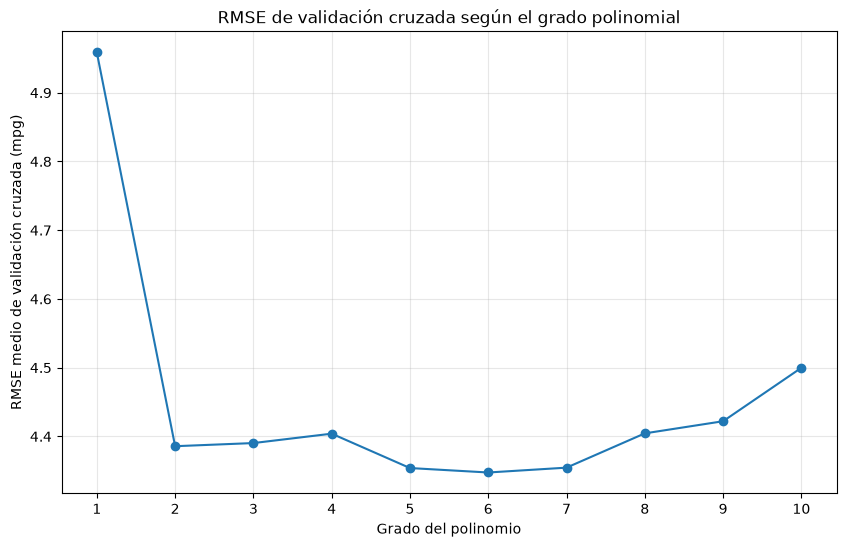

In [67]:
# Paso 09b: tabla y gráfico del RMSE según el grado
tabla_grados = pd.DataFrame(resultados)

display(tabla_grados)

mejor_fila = tabla_grados.loc[tabla_grados["rmse_cv"].idxmin()]

mejor_grado = int(mejor_fila["grado"])
mejor_rmse = mejor_fila["rmse_cv"]

print("Mejor grado:", mejor_grado)
print("RMSE medio:", mejor_rmse)

plt.figure(figsize=(10, 6))

plt.plot(
    tabla_grados["grado"],
    tabla_grados["rmse_cv"],
    marker="o"
)

plt.title("RMSE de validación cruzada según el grado polinomial")
plt.xlabel("Grado del polinomio")
plt.ylabel("RMSE medio de validación cruzada (mpg)")
plt.xticks(range(1, 11))
plt.grid(True, alpha=0.3)
plt.show()

<div style="background:#059669;color:#fff;padding:8px 16px;border-radius:8px;font-family:'Segoe UI',sans-serif;font-weight:700;font-size:0.95rem;display:inline-block">Tus respuestas · Paso 09</div>

<ul style="margin:6px 0 0 0;padding-left:18px;line-height:1.55">
<li>¿Cómo cambia el error al aumentar el grado?</li>
R. del primero al segundo cambia mucho, pero los que menos error tuvieron estan entre el 5, 6 y 7
<li>¿El grado con menor error es necesariamente el mejor? Justifica tu elección aplicando el principio de parsimonia (entre modelos de rendimiento similar, se prefiere el más simple).</li>
R. No necesariamente. En la validación cruzada el menor RMSE lo tuvo el grado 6 (~4.35), pero el grado 2 quedó casi igual (~4.39) y a partir del 2 la curva de error ya se aplana. Aplicando el principio de parsimonia, entre modelos de rendimiento similar se prefiere el más simple: el grado 2 captura la curva, mejora claramente al lineal y su ecuación se puede interpretar; además, los grados altos sin escalar dieron coeficientes numéricos inestables (se comprobó en el Paso 10). Por eso elijo el grado 2.
<li>¿Por qué no se debe usar el conjunto de prueba para elegir el grado?</li>
R.  Porque el conjunto de prueba debe reservarse para la evaluación final. Si se utiliza repetidamente para seleccionar el grado, las decisiones del modelo quedan condicionadas por esos datos y la evaluación deja de ser una medida independiente de su capacidad de generalización.
</ul>


<div style="background:linear-gradient(120deg,#4F46E5,#7E22CE);color:#fff;padding:14px 20px;border-radius:10px;margin-top:22px;font-family:'Segoe UI',sans-serif">
<div style="font-family:'Consolas',monospace;font-size:0.72rem;opacity:.85;letter-spacing:.12em">PASO 10</div>
<div style="font-size:1.25rem;font-weight:700">Evaluar el modelo final</div>
</div>

Con el grado ya elegido, el modelo final se evalúa una sola vez con el conjunto de prueba. Además de las métricas, los residuos (valor real menos valor predicho) revelan si el modelo capturó la forma de los datos: si es adecuado, deben dispersarse al azar alrededor de cero, sin formar patrones.

1. Construye una tabla que compare el RMSE y el R² de prueba del modelo lineal y de tu modelo final.
2. Dibuja, uno al lado del otro, los residuos frente a los valores predichos de ambos modelos, con una línea horizontal en cero.
3. Para obtener una ecuación en unidades originales, reentrena tu modelo final sin `StandardScaler` y escribe la ecuación con sus coeficientes.

<div style="border-left:4px solid #7E22CE;background:#F5F3FF;padding:12px 18px;border-radius:0 8px 8px 0;margin:12px 0;font-family:'Segoe UI',sans-serif">
<div style="color:#7E22CE;font-weight:700;font-size:0.78rem;letter-spacing:.08em;text-transform:uppercase">Para entregar · Paso 10</div>
<div style="margin-top:6px">La tabla comparativa, los gráficos de residuos y la ecuación del modelo. Responde:</div>
<ul style="margin:6px 0 0 0;padding-left:18px;line-height:1.55">
<li>¿Cuánto mejoró el modelo final respecto al lineal?</li>
<li>¿Qué patrón observas en los residuos del modelo lineal y qué significa? ¿Desaparece en el modelo final?</li>
<li>Interpreta el signo de cada coeficiente de la ecuación en relación con la forma de la curva.</li>
</ul>
</div>


In [66]:
# Paso 10a: tabla comparativa de RMSE y R² (lineal vs modelo final)

# Modelo final: grado elegido en el Paso 9
mejor_grado = 2

modelo_final = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=mejor_grado, include_bias=False),
    LinearRegression()
)

# Entrenar solamente con los datos de entrenamiento
modelo_final.fit(X_train, y_train)

# Predecir con los datos de prueba
y_pred_final = modelo_final.predict(X_test)

# Métricas del modelo final
rmse_final = np.sqrt(mean_squared_error(y_test, y_pred_final))
r2_final = r2_score(y_test, y_pred_final)

# Tabla comparativa
tabla_comparativa = pd.DataFrame({
    "Modelo": ["Regresión lineal", f"Polinomial grado {mejor_grado}"],
    "RMSE": [rmse, rmse_final],
    "R²": [r2, r2_final]
})

display(tabla_comparativa)

,Modelo,RMSE,R²
0,Regresión lineal,4.706723,0.565968
1,Polinomial grado 2,4.291499,0.639170


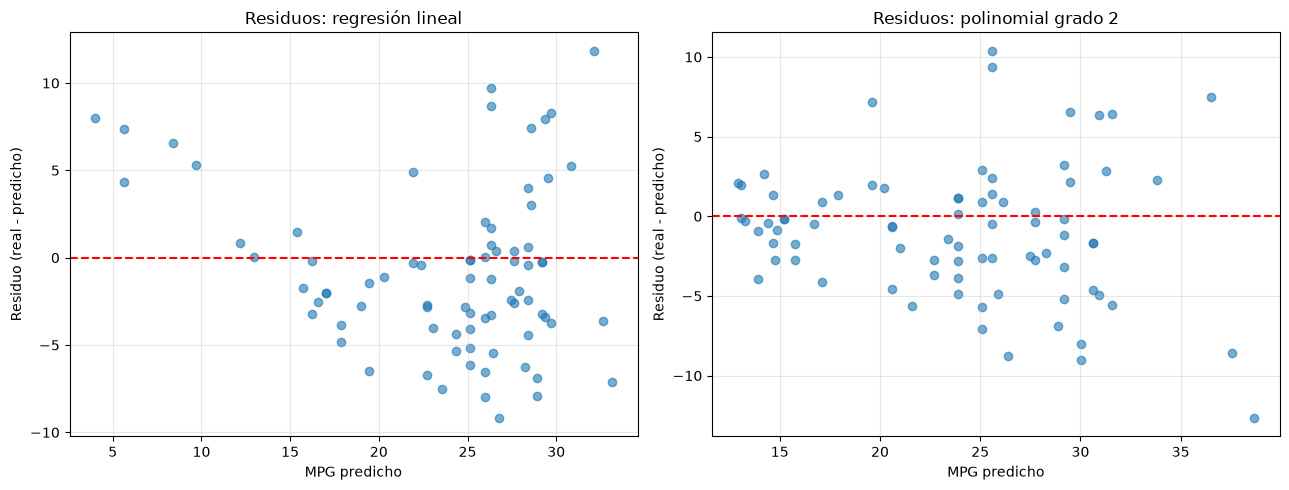

Intercepto: 58.212944359180014
Coeficientes: [-0.48445839  0.0012949 ]


In [65]:
# Paso 10b: residuos de ambos modelos y ecuación final sin StandardScaler

residuos_lineal = y_test.to_numpy() - y_pred
residuos_final = y_test.to_numpy() - y_pred_final

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(y_pred, residuos_lineal, alpha=0.6)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_title("Residuos: regresión lineal")
axes[0].set_xlabel("MPG predicho")
axes[0].set_ylabel("Residuo (real - predicho)")
axes[0].grid(True, alpha=0.3)

axes[1].scatter(y_pred_final, residuos_final, alpha=0.6)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_title(f"Residuos: polinomial grado {mejor_grado}")
axes[1].set_xlabel("MPG predicho")
axes[1].set_ylabel("Residuo (real - predicho)")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Modelo final sin StandardScaler para obtener la ecuación original

poly_original = PolynomialFeatures(
    degree=mejor_grado,
    include_bias=False
)

X_train_poly_original = poly_original.fit_transform(X_train)
X_test_poly_original = poly_original.transform(X_test)

modelo_ecuacion = LinearRegression()
modelo_ecuacion.fit(X_train_poly_original, y_train)

coeficientes = modelo_ecuacion.coef_
intercepto = modelo_ecuacion.intercept_

print("Intercepto:", intercepto)
print("Coeficientes:", coeficientes)

<div style="background:#059669;color:#fff;padding:8px 16px;border-radius:8px;font-family:'Segoe UI',sans-serif;font-weight:700;font-size:0.95rem;display:inline-block">Tus respuestas · Paso 10</div>

<ul style="margin:6px 0 0 0;padding-left:18px;line-height:1.55">
<li>¿Cuánto mejoró el modelo final respecto al lineal?</li>
R. El RMSE bajó de 4.71 a 4.29: el modelo final se equivoca en promedio 0.42 mpg menos por auto. El R² subió de 0.566 a 0.639, o sea ~7 puntos porcentuales más de la variación del rendimiento explicada.
<li>¿Qué patrón observas en los residuos del modelo lineal y qué significa? ¿Desaparece en el modelo final?</li>
R. Los residuos del modelo lineal no se dispersan al azar: forman un arco, una tendencia hacia un lado según la zona del rango — señal de que la recta se equivoca de forma sistemática. En cambio, los residuos del modelo de grado 2 se dispersan uniformemente alrededor de cero sin forma: el modelo de grado 2 sí capturó la curva y el patrón desaparece.
<li>Interpreta el signo de cada coeficiente de la ecuación en relación con la forma de la curva.</li>
R. 58.212 seria el mpg cuando este en cero, o desde donde inicia la curva, -0.48 seria como la la curva va cayendo mientras mas hp tiene el auto porque es un valor negativo, en cambio 0.0012 amortigua la caida y como depende del cuadrado crece rapido a potencias altas, por esa razon al final de la curva se va elevendo la curva
</ul>


<div style="background:linear-gradient(120deg,#4F46E5,#7E22CE);color:#fff;padding:14px 20px;border-radius:10px;margin-top:22px;font-family:'Segoe UI',sans-serif">
<div style="font-family:'Consolas',monospace;font-size:0.72rem;opacity:.85;letter-spacing:.12em">PASO 11</div>
<div style="font-size:1.25rem;font-weight:700">Predecir y reconocer los límites del modelo</div>
</div>

Un polinomio puede comportarse de forma extraña en los extremos del rango de los datos, y más aún fuera de él. Antes de usar el modelo hay que saber dónde son confiables sus predicciones.

1. Predice el rendimiento de autos con potencias de 60, 100, 150 y 200 hp usando tu modelo final.
2. Si tu modelo final es de grado 2, calcula el vértice de la parábola con xᵥ = −β₁ / (2·β₂), usando los coeficientes de la ecuación en unidades originales. Si elegiste otro grado, grafica la curva en un rango amplio de potencias y localiza dónde cambia su tendencia.
3. Compara ese punto con el rango de potencias presente en los datos.

<div style="border-left:4px solid #7E22CE;background:#F5F3FF;padding:12px 18px;border-radius:0 8px 8px 0;margin:12px 0;font-family:'Segoe UI',sans-serif">
<div style="color:#7E22CE;font-weight:700;font-size:0.78rem;letter-spacing:.08em;text-transform:uppercase">Para entregar · Paso 11</div>
<div style="margin-top:6px">La tabla de predicciones y el cálculo del vértice o el análisis gráfico. Responde:</div>
<ul style="margin:6px 0 0 0;padding-left:18px;line-height:1.55">
<li>¿Las predicciones tienen sentido físico en todo el rango?</li>
<li>¿Qué predice el modelo más allá del vértice y por qué eso no es realista?</li>
<li>¿Qué es la extrapolación y por qué es riesgosa con modelos polinomiales?</li>
</ul>
</div>


In [ ]:
# Paso 11a: predicciones con potencias de 60, 100, 150 y 200 hp

# El modelo necesita la misma entrada que durante el entrenamiento:
# un DataFrame con la columna "horsepower" (por eso el doble corchete)
potencias = pd.DataFrame({"horsepower": [60, 100, 150, 200]})

# Predecimos con el modelo final (grado 2, pipeline con StandardScaler)
mpg_predichos = modelo_final.predict(potencias)

# Unimos potencia y predicción en una tabla
tabla_predicciones = pd.DataFrame({
    "horsepower": potencias["horsepower"],
    "mpg predicho": mpg_predichos.round(2)
})

display(tabla_predicciones)


In [ ]:
# Paso 11b: vértice de la parábola y comparación con el rango de los datos

# Reutilizamos los coeficientes de la ecuación en unidades originales (Paso 10b)
b1 = coeficientes[0]   # coeficiente de hp  (negativo: tiro hacia abajo)
b2 = coeficientes[1]   # coeficiente de hp² (positivo: freno de la caída)

# El vértice de la parábola ŷ = b0 + b1·x + b2·x² está en x_v = -b1 / (2·b2)
x_v = -b1 / (2 * b2)

# mpg predicho justo en el vértice (el punto más bajo de la curva)
y_v = intercepto + b1 * x_v + b2 * x_v**2

print(f"Ecuación: mpg = {intercepto:.2f} + ({b1:.5f})·hp + ({b2:.6f})·hp²")
print(f"Vértice:  x_v = -({b1:.5f}) / (2 · {b2:.6f}) = {x_v:.1f} hp")
print(f"mpg mínimo en el vértice: {y_v:.2f}")
print(f"Rango de potencias de los datos: {datos['horsepower'].min():.0f} a {datos['horsepower'].max():.0f} hp")


<div style="background:#059669;color:#fff;padding:8px 16px;border-radius:8px;font-family:'Segoe UI',sans-serif;font-weight:700;font-size:0.95rem;display:inline-block">Tus respuestas · Paso 11</div>

<ul style="margin:6px 0 0 0;padding-left:18px;line-height:1.55">
<li>¿Las predicciones tienen sentido físico en todo el rango?</li>
R. Solo parcialmente. Para 60, 100 y 150 hp los valores (33.81, 22.72 y 14.68 mpg) son creíbles: a mayor potencia, menor rendimiento. Pero a 200 hp el modelo predice 13.12 mpg, que es <strong>más</strong> que el mínimo del vértice (12.90 mpg a 187 hp): la curva ya dio vuelta y afirma que un auto más potente consume menos que uno de 187 hp, lo cual no tiene sentido físico.
<li>¿Qué predice el modelo más allá del vértice y por qué eso no es realista?</li>
R. Más allá de 187 hp la parábola sube sin límite: un auto de 300 hp tendría mejor rendimiento que uno de 187 hp. No es realista porque en la vida real agregar potencia siempre significa más consumo; esa subida es una propiedad matemática del término hp² con coeficiente positivo, no un fenómeno físico.
<li>¿Qué es la extrapolación y por qué es riesgosa con modelos polinomiales?</li>
R. Extrapolar es predecir fuera del rango de datos con el que se entrenó el modelo (aquí, 46–230 hp). Con polinomios es especialmente riesgoso: el término de mayor grado crece más rápido que cualquier recta, así que alejarse del rango hace que el error se dispare y las predicciones se vuelvan absurdas.
</ul>


<div style="background:linear-gradient(120deg,#4F46E5,#7E22CE);color:#fff;padding:14px 20px;border-radius:10px;margin-top:22px;font-family:'Segoe UI',sans-serif">
<div style="font-family:'Consolas',monospace;font-size:0.72rem;opacity:.85;letter-spacing:.12em">PASO 12</div>
<div style="font-size:1.25rem;font-weight:700">Conclusiones</div>
</div>

Cierra el trabajo con una síntesis escrita que responda al problema planteado.

1. Resume el procedimiento que seguiste y compara los resultados del modelo lineal y del modelo final.
2. Explica con tus palabras por qué la regresión polinomial sigue siendo una regresión lineal.

<div style="border-left:4px solid #7E22CE;background:#F5F3FF;padding:12px 18px;border-radius:0 8px 8px 0;margin:12px 0;font-family:'Segoe UI',sans-serif">
<div style="color:#7E22CE;font-weight:700;font-size:0.78rem;letter-spacing:.08em;text-transform:uppercase">Para entregar · Paso 12</div>
<div style="margin-top:6px">Una conclusión de media página que responda:</div>
<ul style="margin:6px 0 0 0;padding-left:18px;line-height:1.55">
<li>¿Qué forma tiene la relación entre potencia y rendimiento?</li>
<li>¿Qué grado recomendarías y por qué?</li>
<li>¿Qué limitaciones tiene el modelo y en qué rango de potencias confiarías en sus predicciones?</li>
</ul>
</div>


<div style="background:#059669;color:#fff;padding:8px 16px;border-radius:8px;font-family:'Segoe UI',sans-serif;font-weight:700;font-size:0.95rem;display:inline-block">Tus respuestas · Paso 12</div>

### Procedimiento y comparación de modelos

Cargamos el dataset `mpg.csv` (398 automóviles), detectamos 6 valores faltantes en `horsepower` y eliminamos esas filas (1.5 % de los datos). Exploramos las correlaciones numéricas con `mpg`, elegimos `horsepower` como predictor, dividimos los datos 80/20 (`random_state=42`) y comparamos dos modelos: la **regresión lineal simple** (RMSE 4.71, R² 0.566) y la **regresión polinomial de grado 2** (RMSE 4.29, R² 0.639). El modelo polinomial reduce el error típico en ~0.42 mpg y explica ~7 puntos porcentuales más de la variación del rendimiento. Los residuos lo confirman: el modelo lineal deja un patrón en arco (sesgo sistemático), mientras que los residuos del modelo polinomial se dispersan sin forma alrededor de cero — la curva sí fue capturada.

### ¿Por qué la regresión polinomial sigue siendo una regresión lineal?

Porque es **lineal en los coeficientes**. La ecuación `mpg = 58.21 − 0.48·hp + 0.0013·hp²` se puede reescribir como ŷ = β₀ + β₁·z₁ + β₂·z₂ donde z₁ = hp y z₂ = hp² son solo columnas nuevas de la tabla. Los pesos β₀, β₁ y β₂ se buscan con los mismos métodos lineales (mínimos cuadrados); lo que se transforma son las **variables de entrada**, no la forma del modelo respecto a sus parámetros.

### Respuestas finales

- **¿Qué forma tiene la relación entre potencia y rendimiento?** Una curva descendente y convexa: caída fuerte a bajas potencias que se aplana a altas potencias (la nube de puntos del Paso 05).
- **¿Qué grado recomiendas y por qué?** El **grado 2**: es el modelo curvo más simple (principio de parsimonia), mejora claramente al lineal (R² 0.566 → 0.639) y su ecuación se puede interpretar y analizar matemáticamente (vértice), algo inviable con grados altos sin escalar.
- **¿Qué limitaciones tiene y a qué rango confías?** Usa una sola variable: explica el 64 % de la variación (variables como `weight` o `cylinders` aportarían el resto). Es confiable dentro del rango 46–230 hp, sobre todo lejos de los extremos; no se debe confiar en predicciones más allá del vértice (~187 hp) ni fuera del rango de los datos (extrapolación).


<div style="background:linear-gradient(120deg,#D97706,#B45309);color:#fff;padding:14px 20px;border-radius:10px;margin-top:22px;font-family:'Segoe UI',sans-serif">
<div style="font-family:'Consolas',monospace;font-size:0.72rem;opacity:.85;letter-spacing:.12em">RETO ADICIONAL (OPCIONAL)</div>
<div style="font-size:1.25rem;font-weight:700">Ir más allá de una variable</div>
</div>

Si terminaste los pasos anteriores, extiende el análisis para comprobar si otros predictores mejoran el modelo.

1. Repite el procedimiento de los Pasos 05 a 10 usando `weight` o `displacement` como predictor, y compara el grado elegido y las métricas con las de `horsepower`.
2. Entrena un modelo polinomial con varias variables a la vez (por ejemplo `horsepower`, `weight` y `model_year`) y compáralo con tu mejor modelo de una sola variable.

<div style="border-left:4px solid #7E22CE;background:#F5F3FF;padding:12px 18px;border-radius:0 8px 8px 0;margin:12px 0;font-family:'Segoe UI',sans-serif">
<div style="color:#7E22CE;font-weight:700;font-size:0.78rem;letter-spacing:.08em;text-transform:uppercase">Para entregar · Reto adicional</div>
<div style="margin-top:6px">La tabla comparativa de todos los modelos probados. Responde:</div>
<ul style="margin:6px 0 0 0;padding-left:18px;line-height:1.55">
<li>¿Qué predictor individual funcionó mejor?</li>
<li>¿Cuánto mejora el modelo al combinar varias variables?</li>
<li>¿Cuántas columnas genera `PolynomialFeatures` con tres variables y grado 2, y qué representan las columnas nuevas?</li>
</ul>
</div>


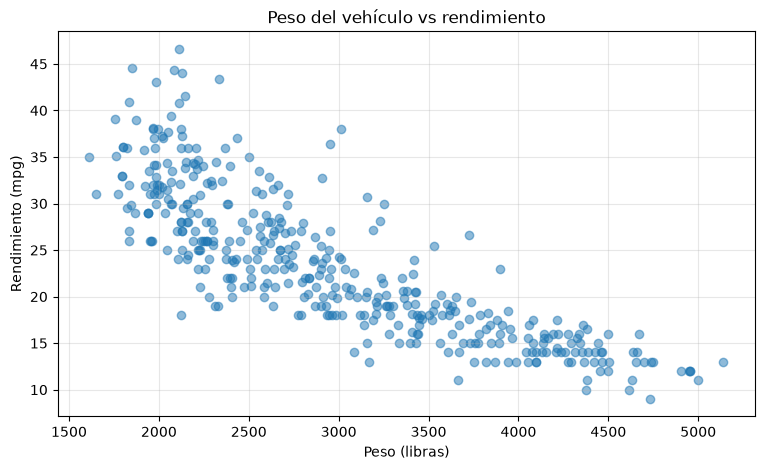

Mejor grado (weight): 2
Lineal weight       -> RMSE 3.8594 | R2 0.7230
Grado 2 weight        -> RMSE 3.6264 | R2 0.7554


In [70]:
# Reto: repetir los Pasos 05–10 con weight como predictor

# Paso 05: dispersión weight vs mpg
plt.figure(figsize=(9, 5))
plt.scatter(df["weight"], df["mpg"], alpha=0.5)
plt.title("Peso del vehículo vs rendimiento")
plt.xlabel("Peso (libras)")
plt.ylabel("Rendimiento (mpg)")
plt.grid(True, alpha=0.3)
plt.show()

# Pasos 04/06: preparar datos y dividir 80/20
datos_weight = df[["weight", "mpg"]].dropna()
X_w = datos_weight[["weight"]]
y_w = datos_weight["mpg"]

X_w_train, X_w_test, y_w_train, y_w_test = train_test_split(
    X_w, y_w, test_size=0.2, random_state=42
)

# Paso 07: modelo lineal base con weight
modelo_lineal_w = make_pipeline(StandardScaler(), LinearRegression())
modelo_lineal_w.fit(X_w_train, y_w_train)
y_w_pred_lineal = modelo_lineal_w.predict(X_w_test)

rmse_w_lineal = np.sqrt(mean_squared_error(y_w_test, y_w_pred_lineal))
r2_w_lineal = r2_score(y_w_test, y_w_pred_lineal)

# Paso 09: elegir el grado con validación cruzada (1 a 10)
kf_w = KFold(n_splits=10, shuffle=True, random_state=42)
resultados_w = []

for grado in range(1, 11):
    modelo_w = make_pipeline(
        StandardScaler(),
        PolynomialFeatures(degree=grado, include_bias=False),
        LinearRegression()
    )
    scores_w = cross_val_score(
        modelo_w, X_w_train, y_w_train,
        cv=kf_w, scoring="neg_root_mean_squared_error"
    )
    resultados_w.append({"grado": grado, "rmse_cv": -scores_w.mean()})

tabla_w = pd.DataFrame(resultados_w)
mejor_grado_w = int(tabla_w.loc[tabla_w["rmse_cv"].idxmin(), "grado"])

# Pasos 08/10: modelo polinomial con el mejor grado y métricas de prueba
modelo_poly_w = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=mejor_grado_w, include_bias=False),
    LinearRegression()
)
modelo_poly_w.fit(X_w_train, y_w_train)
y_w_pred_poly = modelo_poly_w.predict(X_w_test)

rmse_w_poly = np.sqrt(mean_squared_error(y_w_test, y_w_pred_poly))
r2_w_poly = r2_score(y_w_test, y_w_pred_poly)

print("Mejor grado (weight):", mejor_grado_w)
print(f"Lineal weight       -> RMSE {rmse_w_lineal:.4f} | R2 {r2_w_lineal:.4f}")
print(f"Grado {mejor_grado_w} weight        -> RMSE {rmse_w_poly:.4f} | R2 {r2_w_poly:.4f}")


In [71]:
# Reto: modelo polinomial multivariable y comparación con tu mejor modelo de una sola variable

# Tres predictores numéricos a la vez
X_multi = df[["horsepower", "weight", "model_year"]].dropna()
y_multi = df.loc[X_multi.index, "mpg"]

X_m_train, X_m_test, y_m_train, y_m_test = train_test_split(
    X_multi, y_multi, test_size=0.2, random_state=42
)

# ¿Cuántas columnas genera PolynomialFeatures(degree=2) con 3 variables?
poly_multi = PolynomialFeatures(degree=2, include_bias=False)
X_m_train_poly = poly_multi.fit_transform(X_m_train)
nombres_multi = poly_multi.get_feature_names_out(X_m_train.columns)

print("Columnas generadas:", len(nombres_multi))
print(list(nombres_multi))

# Pipeline multivariable grado 2
modelo_multi = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression()
)
modelo_multi.fit(X_m_train, y_m_train)
y_m_pred = modelo_multi.predict(X_m_test)

rmse_multi = np.sqrt(mean_squared_error(y_m_test, y_m_pred))
r2_multi = r2_score(y_m_test, y_m_pred)

print(f"\nMultivariable grado 2 -> RMSE {rmse_multi:.4f} | R2 {r2_multi:.4f}")

# Tabla comparativa de todos los modelos probados
comparacion = pd.DataFrame({
    "Modelo": [
        "Lineal (horsepower)",
        f"Polinomial grado {mejor_grado} (horsepower)",
        "Lineal (weight)",
        f"Polinomial grado {mejor_grado_w} (weight)",
        "Multivariable grado 2 (hp + weight + model_year)",
    ],
    "RMSE": [rmse, rmse_final, rmse_w_lineal, rmse_w_poly, rmse_multi],
    "R²": [r2, r2_final, r2_w_lineal, r2_w_poly, r2_multi],
})

display(comparacion)


Columnas generadas: 9
['horsepower', 'weight', 'model_year', 'horsepower^2', 'horsepower weight', 'horsepower model_year', 'weight^2', 'weight model_year', 'model_year^2']

Multivariable grado 2 -> RMSE 2.6115 | R2 0.8664


,Modelo,RMSE,R²
0,Lineal (horsepower),4.706723,0.565968
1,Polinomial grado 6 (horsepower),4.291499,0.639170
2,Lineal (weight),3.859386,0.722971
3,Polinomial grado 2 (weight),3.626365,0.755414
4,Multivariable grado 2 (hp + weight + model_year),2.611453,0.866387


<div style="background:#059669;color:#fff;padding:8px 16px;border-radius:8px;font-family:'Segoe UI',sans-serif;font-weight:700;font-size:0.95rem;display:inline-block">Tus respuestas · Reto adicional</div>

<ul style="margin:6px 0 0 0;padding-left:18px;line-height:1.55">
<li>¿Qué predictor individual funcionó mejor?</li>
R. <strong>weight</strong>. Con el mismo grado 2 alcanzó R² 0.755 y RMSE 3.63, mientras que horsepower quedó en R² 0.639 y RMSE 4.29. Incluso el modelo <em>lineal</em> con weight (R² 0.723) le gana al polinomial de horsepower: el peso del auto explica mejor el rendimiento que la potencia sola. La validación cruzada además volvió a elegir el grado 2 (RMSE CV 4.25, el más bajo de 1 a 10).
<li>¿Cuánto mejora el modelo al combinar varias variables?</li>
R. Bastante: el modelo multivariable de grado 2 (horsepower + weight + model_year) bajó el RMSE de prueba a <strong>2.61</strong> y subió el R² a <strong>0.866</strong>, contra 3.63 y 0.755 del mejor modelo de una sola variable. Pasa de explicar el 63.9 % de la variación (horsepower solo) al 86.6 %: cada variable aporta lo que las otras no cubren.
<li>¿Cuántas columnas genera PolynomialFeatures con tres variables y grado 2, y qué representan las columnas nuevas?</li>
R. Genera <strong>9 columnas</strong>: las 3 originales (horsepower, weight, model_year); 3 cuadrados (horsepower², weight², model_year²), que añaden la curvatura de cada variable; y 3 términos de interacción (horsepower·weight, horsepower·model_year, weight·model_year), que permiten que el efecto de una variable dependa del valor de las otras.
</ul>
